# Baseline Model: College Football Stadium Turnout

Train a Logistic Regression baseline using the existing
train/test split and save test metrics for future comparisons.

##Import libraries

In [1]:
from pathlib import Path  
import json  
import joblib
import pandas as pd  
import matplotlib.pyplot as plt
import os

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

In [2]:
# check both possible locations for the prepared data
possible_dirs = [
    Path("../data/processed/features"),
    Path("data/processed/features"),
]

# choose the first folder containing the training file
FEATURES_DIR = next(
    (folder for folder in possible_dirs
     if (folder / "train_features.csv").exists()),
    None,
)

# stop with a clear message if the training file is missing
if FEATURES_DIR is None:
    raise FileNotFoundError(
        "could not find train_features.csv. "
        "check data/processed/features in your project."
    )

# load the existing training and test sets
train = pd.read_csv(FEATURES_DIR / "train_features.csv")
test = pd.read_csv(FEATURES_DIR / "test_features.csv")

# load the saved feature names and target definitions
with open(FEATURES_DIR / "feature_config.json") as f:
    config = json.load(f)

# convert class codes from text to integers
CLASS_LABELS = {
    int(code): name
    for code, name in config["class_labels"].items()
}

# show the data location, row and column counts, and target labels
print("data folder:", FEATURES_DIR.resolve())
print("training data shape:", train.shape)
print("test data shape:", test.shape)
print("target labels:", CLASS_LABELS)

# list the columns to check what was loaded
print("\ncolumns:")
print(train.columns.tolist())

# preview the first five training rows
print("\nfirst five training rows:")
display(train.head())

data folder: C:\Users\emirl\Sports-Analytics-1B-assessing-football-stadium-attendance-and-experience\data\processed\features
training data shape: (1559, 36)
test data shape: (806, 36)
target labels: {0: 'low', 1: 'medium', 2: 'high'}

columns:
['week', 'conferenceGame', 'away_is_fcs', 'homePregameElo', 'elo_diff', 'elo_abs_diff', 'log_capacity', 'latitude', 'longitude', 'away_travel_km', 'home_prior_turnout', 'home_turnout_trend', 'home_prior_games', 'away_draw_lift_prior', 'homeConference_ACC', 'homeConference_American Athletic', 'homeConference_Big 12', 'homeConference_Big Ten', 'homeConference_Conference USA', 'homeConference_FBS Independents', 'homeConference_Mid-American', 'homeConference_Mountain West', 'homeConference_Pac-12', 'homeConference_SEC', 'homeConference_Sun Belt', 'day_type_friday', 'day_type_other_day', 'day_type_saturday', 'kickoff_slot_afternoon', 'kickoff_slot_evening', 'kickoff_slot_midday', 'kickoff_slot_unknown', 'target', 'turnout_rate', 'id', 'season']

first

,week,conferenceGame,away_is_fcs,homePregameElo,elo_diff,elo_abs_diff,log_capacity,latitude,longitude,away_travel_km,...,day_type_other_day,day_type_saturday,kickoff_slot_afternoon,kickoff_slot_evening,kickoff_slot_midday,kickoff_slot_unknown,target,turnout_rate,id,season
0,1.0,1.0,0.0,1500.0,131.0,131.0,10.085851,33.820310,-85.766466,1948.676029,...,0.0,1.0,1.0,0.0,0.0,0.0,1,0.749250,401520145,2023
1,1.0,0.0,0.0,1322.0,248.0,248.0,10.320354,32.279749,-106.741136,3200.131321,...,0.0,1.0,1.0,0.0,0.0,0.0,0,0.506080,401525450,2023
2,1.0,0.0,0.0,1322.0,76.0,76.0,10.605371,36.143558,-86.808772,730.081243,...,0.0,1.0,0.0,1.0,0.0,0.0,0,0.530533,401520147,2023
3,1.0,0.0,0.0,1663.0,201.0,201.0,11.446871,34.014010,-118.287896,489.554948,...,0.0,1.0,1.0,0.0,0.0,0.0,0,0.677417,401523986,2023
4,1.0,1.0,0.0,1251.0,179.0,179.0,10.328788,32.532238,-92.656019,1409.162158,...,0.0,1.0,0.0,1.0,0.0,0.0,0,0.532647,401520146,2023


In [3]:
# remove the target, attendance ratio, and tracking columns
NON_FEATURES = ["target", "turnout_rate", "id", "season"]

X_train = train.drop(columns=NON_FEATURES)
X_test = test.drop(columns=NON_FEATURES)

# store the class we want the model to predict
y_train = train["target"].astype(int)
y_test = test["target"].astype(int)

# check that both sets have the expected features in the same order
assert X_train.columns.tolist() == config["output_columns"]
assert X_test.columns.tolist() == X_train.columns.tolist()

# check that the prepared features and targets have no missing values
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()
assert train["target"].notna().all()
assert test["target"].notna().all()

# check that no game appears in both sets
assert set(train["id"]).isdisjoint(set(test["id"]))

# show the feature counts
print("training features:", X_train.shape)
print("test features:", X_test.shape)

# show how many games belong to each turnout class
class_counts = pd.DataFrame({
    "train_count": y_train.value_counts(),
    "test_count": y_test.value_counts(),
}).sort_index()

class_counts.index = class_counts.index.map(CLASS_LABELS)
class_counts.index.name = "turnout_class"

display(class_counts)
# target is the outcome to predict, so it is kept separate from the features
# turnout_rate reveals the answer, so it is excluded to prevent leakage
# id and season are tracking columns, so they are also excluded

training features: (1559, 32)
test features: (806, 32)


,train_count,test_count
turnout_class,,
low,520,238
medium,519,311
high,520,257


In [4]:
# scale features using training data, then train logistic regression
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42,
    )),
])

# learn to predict the most common training class for comparison
dummy_model = DummyClassifier(strategy="most_frequent")

# train both models using only the training set
baseline_model.fit(X_train, y_train)
dummy_model.fit(X_train, y_train)

print("logistic regression training complete")
print("dummy model training complete")
print("classes:", baseline_model.classes_)

logistic regression training complete
dummy model training complete
classes: [0 1 2]


In [5]:
# generate predicted classes and probabilities for the test games
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)

dummy_pred = dummy_model.predict(X_test)
dummy_prob = dummy_model.predict_proba(X_test)

# calculate metrics for all three turnout classes
def evaluate_model(name, predictions, probabilities, classes):
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision_macro": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "roc_auc_macro": roc_auc_score(
            y_test,
            probabilities,
            labels=classes,
            multi_class="ovr",
            average="macro",
        ),
    }

# compare logistic regression with the majority-class reference
metrics_df = pd.DataFrame([
    evaluate_model(
        "logistic_regression", y_pred, y_prob, baseline_model.classes_
    ),
    evaluate_model(
        "majority_class_dummy", dummy_pred, dummy_prob, dummy_model.classes_
    ),
])

# display rounded metrics while keeping full values for saving
display(metrics_df.round(4))

,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_macro
0,logistic_regression,0.7568,0.7620,0.7680,0.7612,0.9093
1,majority_class_dummy,0.2953,0.0984,0.3333,0.1520,0.5000


              precision    recall  f1-score   support

         low       0.84      0.82      0.83       238
      medium       0.73      0.62      0.67       311
        high       0.72      0.87      0.79       257

    accuracy                           0.76       806
   macro avg       0.76      0.77      0.76       806
weighted avg       0.76      0.76      0.75       806



predicted,low,medium,high
actual,,,
low,194,44,0
medium,33,192,86
high,5,28,224


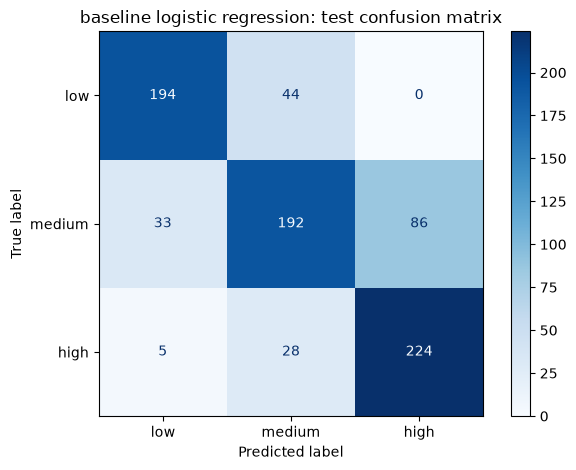

In [6]:
# use the class order learned by the model
labels = baseline_model.classes_
class_names = [CLASS_LABELS[int(label)] for label in labels]

# show precision, recall, and f1 for each turnout class
print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=class_names,
    zero_division=0,
))

# count actual versus predicted classes
cm = confusion_matrix(y_test, y_pred, labels=labels)

# display the counts with actual classes in rows
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names,
)
cm_df.index.name = "actual"
cm_df.columns.name = "predicted"
display(cm_df)

# plot the confusion matrix with correct predictions on the diagonal
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
).plot(cmap="Blues")

plt.title("baseline logistic regression: test confusion matrix")
plt.tight_layout()
plt.show()

In [7]:
# save results inside the project's results folder
PROJECT_DIR = FEATURES_DIR.resolve().parents[2]
RESULTS_DIR = PROJECT_DIR / "results" / "baseline"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# save the comparison metrics with full precision
metrics_df.to_csv(
    RESULTS_DIR / "baseline_metrics.csv",
    index=False,
)

# save per-class metrics
report = classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(report).T.to_csv(
    RESULTS_DIR / "classification_report.csv"
)

# save the confusion matrix as a table and image
cm_df.to_csv(RESULTS_DIR / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
).plot(ax=ax, cmap="Blues")

ax.set_title("baseline logistic regression: test confusion matrix")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150)
plt.close(fig)

# save each test game's actual class and model predictions
test_predictions = test[["id", "season", "target"]].copy()
test_predictions = test_predictions.rename(
    columns={"target": "actual_target"}
)
test_predictions["predicted_target"] = y_pred
test_predictions["dummy_prediction"] = dummy_pred

# save probabilities in the model's class order
for column, label in enumerate(labels):
    class_name = CLASS_LABELS[int(label)]
    test_predictions[f"prob_{class_name}"] = y_prob[:, column]

test_predictions.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False,
)

# save the fitted scaler and logistic regression together
joblib.dump(
    baseline_model,
    RESULTS_DIR / "logistic_regression_baseline.joblib",
)

# record the feature order, target definitions, and training settings
metadata = {
    "model": "logistic_regression",
    "train_seasons": sorted(train["season"].unique().tolist()),
    "test_seasons": sorted(test["season"].unique().tolist()),
    "train_games": len(train),
    "test_games": len(test),
    "feature_columns": X_train.columns.tolist(),
    "class_labels": CLASS_LABELS,
    "low_max": config["low_max"],
    "medium_max": config["medium_max"],
    "model_parameters": baseline_model.named_steps["model"].get_params(),
    "evaluation_note": (
        "historical features include earlier games within the test season; "
        "evaluation represents predictions as the season progresses"
    ),
}

with open(RESULTS_DIR / "baseline_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# show where the files were saved
print("results saved to:", RESULTS_DIR)
print("\nsaved files:")
for file in sorted(RESULTS_DIR.iterdir()):
    print(file.name)

results saved to: C:\Users\emirl\Sports-Analytics-1B-assessing-football-stadium-attendance-and-experience\results\baseline

saved files:
baseline_metadata.json
baseline_metrics.csv
classification_report.csv
confusion_matrix.csv
confusion_matrix.png
logistic_regression_baseline.joblib
test_predictions.csv


## Save dataframes as a csv files for reusability

In [8]:
out_dir = "../data/train_test_df"
os.makedirs(out_dir, exist_ok=True)

X_train.to_csv(os.path.join(out_dir, "X_train.csv"), index=False)
X_test.to_csv(os.path.join(out_dir, "X_test.csv"), index=False)
y_train.to_csv(os.path.join(out_dir, "y_train.csv"), index=False)
y_test.to_csv(os.path.join(out_dir, "y_test.csv"), index=False)

## Baseline Results

### Approach

A Logistic Regression baseline was trained to predict low, medium,
or high stadium turnout. The existing split was used without creating
a new split:

- training: 1,559 games from 2023–2024
- testing: 806 games from 2025
- predictors: 32 prepared features

The target was kept separate from the predictors. `turnout_rate`
was excluded because it reveals the answer, and `id` and `season`
were excluded because they are tracking columns.

Features were standardized using training data only. A majority-class
dummy classifier was also trained as a simple comparison.

### Test Metrics

| metric | logistic regression | majority-class dummy |
|---|---:|---:|
| accuracy | 0.7568 | 0.2953 |
| macro precision | 0.7620 | 0.0984 |
| macro recall | 0.7680 | 0.3333 |
| macro f1 | 0.7612 | 0.1520 |
| macro roc auc (one-vs-rest) | 0.9093 | 0.5000 |

Logistic Regression correctly classified 610 of 806 test games,
achieving 75.68% accuracy. It exceeded the dummy model's accuracy
by 46.15 percentage points.

### Findings

- low turnout had the highest precision, approximately 84%.
- high turnout had the highest recall, approximately 87%.
- medium turnout was the hardest class to identify, with approximately
  62% recall.
- the most common error was predicting high turnout for games with
  actual medium turnout: 86 games.

### Scope and Limitations

The current target has three classes, although the original project
overview describes binary classification. This baseline follows the
existing prepared target; the team should confirm the final target
definition with the advisor.

Team performance is represented through pregame Elo features.
Weather and ticket price are not yet included.

Historical attendance features use earlier games within the test
season. These results represent predictions as the season progresses,
when earlier attendance is available, rather than predicting the
entire season before it starts.

No hyperparameter tuning was performed for this baseline. Future
model selection should use validation within the training data rather
than using test metrics to choose settings.

### Saved outputs

Results are saved in `results/baseline/`, including comparison metrics,
the classification report, confusion matrix, test predictions, model
metadata, and the trained Logistic Regression pipeline.

These results establish a reference point for later experiments
using the same target definition, split, and evaluation metrics.